In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',60)
sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv('../data/diabetic_data.csv', na_values="?")
df.head(10)

C:\Users\hp\AppData\Local\Temp\ipykernel_11956\2274711529.py:1: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/diabetic_data.csv', na_values="?")


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,NaN,NaN,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,NaN,NaN,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
print(df.shape)

(101766, 50)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [5]:
print(df['readmitted'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


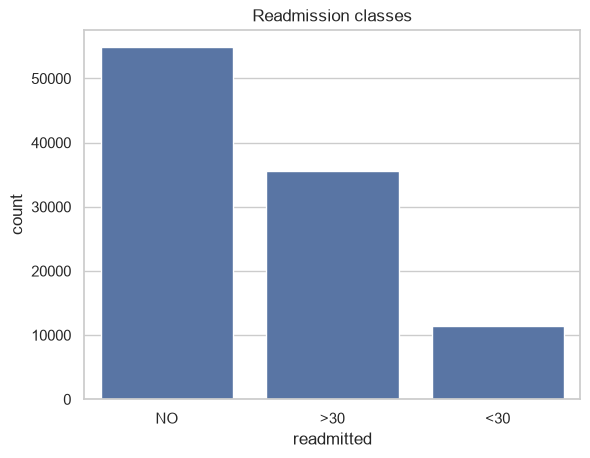

In [6]:
print(df['readmitted'].value_counts(normalize=True).round(3))

sns.countplot(data=df, x='readmitted', order=['NO','>30','<30'])
plt.title('Readmission classes')
plt.show()

In [7]:
missing=(df.isna().mean()*100).sort_values(ascending=False)
missing[missing>0].round(2)

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

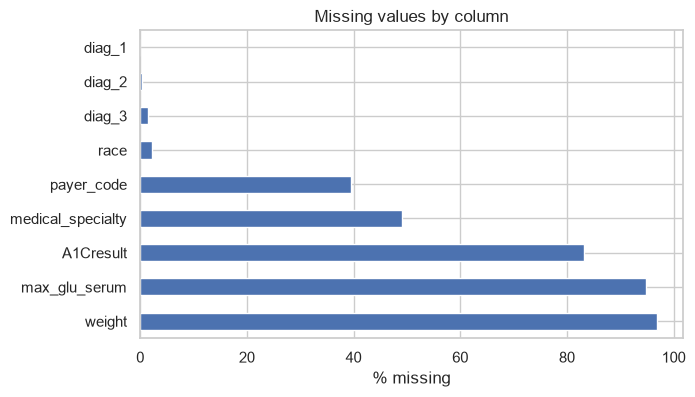

In [8]:
missing[missing>0].plot(kind='barh',figsize=(7,4))
plt.xlabel('% missing')
plt.title('Missing values by column')
plt.show()

In [9]:
print('Rows:',len(df))
print('Unique encounters:',df['encounter_id'].nunique())
print('Unique patients:',df['patient_nbr'].nunique())

Rows: 101766
Unique encounters: 101766
Unique patients: 71518


In [10]:
visits=df['patient_nbr'].value_counts()
print(visits.describe())
print('Patients with >1 encounter:',(visits>1).sum())

count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64
Patients with >1 encounter: 16773


In [11]:
nunique=df.nunique().sort_values()
nunique.head(10)

citoglipton                 1
examide                     1
acetohexamide               2
glipizide-metformin         2
tolbutamide                 2
troglitazone                2
metformin-rosiglitazone     2
glimepiride-pioglitazone    2
metformin-pioglitazone      2
change                      2
dtype: int64

In [12]:
for col in nunique[nunique <= 2].index:
    print(col, df[col].value_counts().to_dict())

citoglipton {'No': 101766}
examide {'No': 101766}
acetohexamide {'No': 101765, 'Steady': 1}
glipizide-metformin {'No': 101753, 'Steady': 13}
tolbutamide {'No': 101743, 'Steady': 23}
troglitazone {'No': 101763, 'Steady': 3}
metformin-rosiglitazone {'No': 101764, 'Steady': 2}
glimepiride-pioglitazone {'No': 101765, 'Steady': 1}
metformin-pioglitazone {'No': 101765, 'Steady': 1}
change {'No': 54755, 'Ch': 47011}
diabetesMed {'Yes': 78363, 'No': 23403}


In [13]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
            "num_medications", "number_outpatient", "number_emergency",
            "number_inpatient", "number_diagnoses"]

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


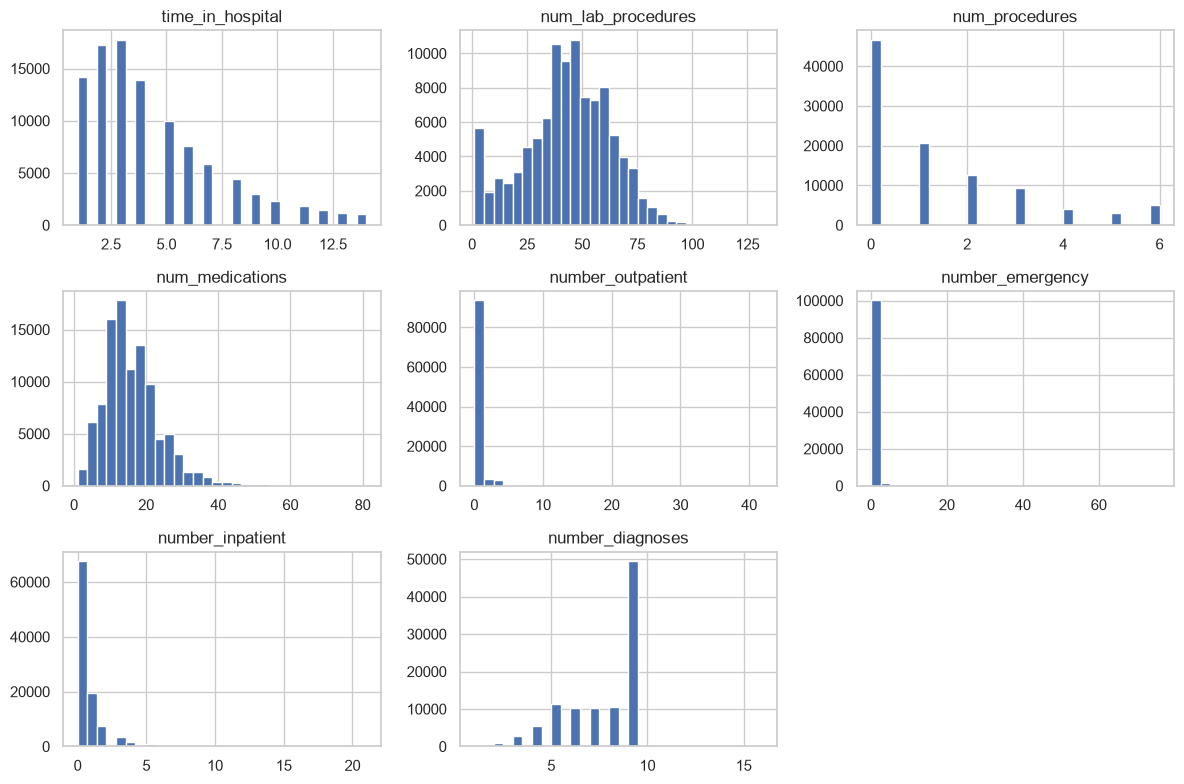

In [14]:
df[num_cols].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

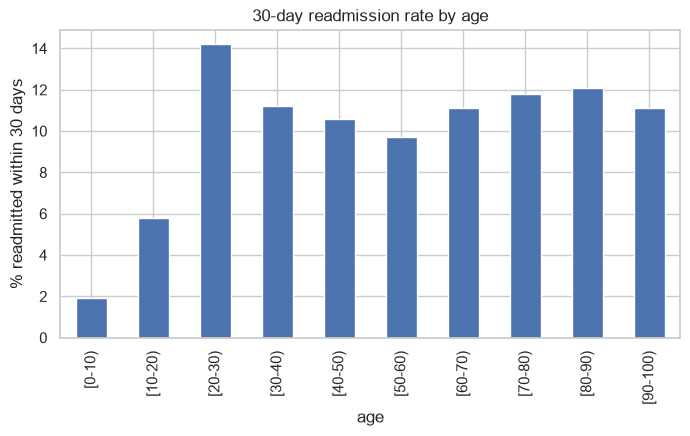

In [15]:
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

age_rate = df.groupby("age")["readmit_30"].mean().mul(100).round(1)
age_rate.plot(kind="bar", figsize=(8, 4))
plt.ylabel("% readmitted within 30 days")
plt.title("30-day readmission rate by age")
plt.show()

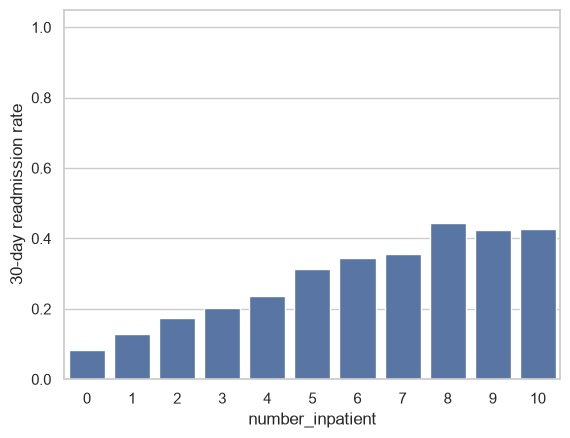

In [16]:
# Prior inpatient visits vs. readmission
sns.barplot(data=df, x="number_inpatient", y="readmit_30", errorbar=None)
plt.ylabel("30-day readmission rate")
plt.xlim(-0.5, 10.5)
plt.show()

In [17]:
not_eligible = [11, 13, 14, 19, 20, 21]   # died or went to hospice
mask = df["discharge_disposition_id"].isin(not_eligible)
print("Died/hospice encounters:", mask.sum())
print(df[mask]["readmitted"].value_counts())


Died/hospice encounters: 2423
readmitted
NO     2337
<30      43
>30      43
Name: count, dtype: int64


## EDA findings → cleaning decisions
- `?` = missing. Converted to NaN on load. .
- Target: `readmitted`; plan to use binary `<30` vs rest (~11% positive, imbalanced).
- Drop `weight` (~97% missing). Missing `payer_code`, `medical_specialty`, `race` become a "Missing" category.
- Drop `encounter_id`, `patient_nbr` as features.
- Drop constant columns (`examide`, `citoglipton`).
- Remove died/hospice encounters (IDs 11, 13, 14, 19, 20, 21).
- Repeated patients → keep first encounter per patient (decided in cleaning).
- ID columns are categorical, not numeric.
- Strongest early signal: `number_inpatient`.